## DE analysis Stromal growth factors and signalling factors

In [1]:
import os
import sys
from datetime import datetime
today = datetime.today().strftime('%Y-%m-%d')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
import hdf5plugin

# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment'
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')


In [2]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # to show output from all the lines in a cells
pd.set_option('display.max_column',None) # display all the columns in pandas
pd.options.display.max_rows = 100

In [3]:
# Define plot and path dirs
plot_path = os.path.join(repo_path, 'plots')
data_path = os.path.join(repo_path, 'data')
model_path = os.path.join(repo_path, 'models')
# Define plot and path dirs
results_path = os.path.join(repo_path, 'results')
general_data_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data'

In [4]:
# Formatting
from matplotlib import font_manager
font_manager.fontManager.addfont("/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf")
#plt.style.use('/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing.mplstyle')


In [5]:
# Import custom scripts
from utils import get_latest_version,update_obs,freq_by_donor
from anno_levels import get_ct_levels, get_ct_palette, age_group_levels, age_group_palette
from plotting.utils import plot_grouped_boxplot, calc_figsize
from plotting.colors import thyAgeing_colors

In [6]:
import importlib, de_viz; importlib.reload(de_viz)

<module 'de_viz' from '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts/de_viz.py'>

In [7]:
from de_viz import (
    plot_de_dotplot2, plot_de_dotplot2_grouped,plot_de_dotplot3_grouped,
    select_top_de, build_candidate_pools,
    load_hallmark, run_ora, load_tec_markers, markers_flat,
    plot_volcano_grid,
)

In [8]:
plt.style.use('/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing.mplstyle')

## Load adata

In [9]:
# Load adata
object_version = 'v6_2026-05-01'
adata = ad.read_h5ad(f'{general_data_path}/objects/rna/thyAgeing_all_scvi_{object_version}.zarr')
# Add final annotations to adata and remove non-annotated cells
ct_anno = pd.read_csv(f'{general_data_path}/objects/rna/thyAgeing_all_scvi_v5_2025-10-15_curatedAnno_v11.csv', index_col = 0)

for c in ct_anno.columns:
    if c in adata.obs.columns:
        adata.obs.drop(c, axis = 1, inplace = True)
adata.obs = adata.obs.join(ct_anno)

adata = adata[~adata.obs['taa_l5'].isnull(),].copy()
# Update metadata
latest_meta_path = get_latest_version(dir = f'{general_data_path}/metadata', file_prefix='Thymus_ageing_metadata')
latest_meta = pd.read_excel(latest_meta_path)

update_obs(adata, latest_meta, on = 'index')


Latest file: Thymus_ageing_metadata_v30_2026-07-09.xlsx
No columns specified to update. Automatically determining columns to update...
Updating columns: ['age', 'age_cont', 'age_group', 'age_group2', 'age_months', 'age_num', 'age_unit', 'chemistry_detail', 'chemistry_orig', 'chemistry_simple', 'cite', 'comment', 'donor', 'health_status', 'in_HTSA', 'library', 'library_bcr', 'library_tcr_ab', 'library_tcr_gd', 'origin_institute', 'path_bcr', 'path_cellbender_gex', 'path_cellranger_arc', 'path_raw_gex', 'path_tcr_ab', 'path_tcr_gd', 'public_data', 'research_no', 'sample', 'sex', 'sort', 'sort_type', 'starsolo_version', 'study', 'type']
On columns: index


## Load DE results

In [10]:
import pickle as pkl
# taa_l3 DESeq2 age-DE, both contrasts: dict{cell_type: df} -> flattened long form
with open(f'{general_data_path}/analyses/dea/thyAgeing_dea_taa_l3_adult_vs_infant_ageEffect.pkl', 'rb') as f:
    de_ad_dict = pkl.load(f)
with open(f'{general_data_path}/analyses/dea/thyAgeing_dea_taa_l3_paed_vs_infant_ageEffect.pkl', 'rb') as f:
    de_pd_dict = pkl.load(f)

def _flatten(d, contrast):
    df = (pd.concat([v for v in d.values()], keys=d.keys(), names=['cell_type'])
            .reset_index().rename(columns={'level_1': 'gene_name'}))
    df['contrast'] = contrast
    df['col_cell_type'] = 'taa_l3'
    df['change'] = np.where((df['padj'] < 0.05) & (df['log2FoldChange'] > 0), 'sign_up',
                    np.where((df['padj'] < 0.05) & (df['log2FoldChange'] < 0), 'sign_dw', 'non_sign'))
    return df

de_ad2inf_lev3 = _flatten(de_ad_dict, 'adult-vs-infant')
de_paed2inf_lev3 = _flatten(de_pd_dict, 'paed-vs-infant')
print(de_ad2inf_lev3.shape, de_paed2inf_lev3.shape)
print('cell types:', sorted(de_ad2inf_lev3['cell_type'].unique()))
de_ad2inf_lev3.head()

(772906, 11) (683445, 11)
cell types: ['B_GC-like', 'B_dev', 'B_mem', 'B_naive', 'B_plasma', 'DC1', 'DC2', 'EC-art', 'EC-cap', 'EC-cap_lipid', 'EC-lymphatic', 'EC-ven', 'Fb-adipo', 'Fb-interlo', 'Fb-med', 'Fb-perilo', 'ILC', 'Mac', 'Mono', 'Myeloid_dev', 'NK', 'Pericyte', 'SMC', 'TEC-EMT', 'TEC-mim', 'T_CD4', 'T_CD4_naive_recirc', 'T_CD4_recirc', 'T_CD8', 'T_CD8_recirc', 'T_CD8αα', 'T_DN', 'T_DN(early)', 'T_DP', 'T_MAIT', 'T_Treg', 'T_Treg_recirc', 'T_αβT(entry)', 'T_γδT', 'aDC', 'cTEC', 'mTECI', 'mTECII', 'mTECIII', 'mcTEC', 'pDC']


,cell_type,gene_name,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,contrast,col_cell_type,change
0,B_GC-like,LINC01409,1.576464,0.546804,0.490449,1.114905,0.264891,0.536246,adult-vs-infant,taa_l3,non_sign
1,B_GC-like,LINC01128,2.235932,0.182818,0.402442,0.454272,0.649633,0.838361,adult-vs-infant,taa_l3,non_sign
2,B_GC-like,LINC00115,0.458877,-0.244832,0.866254,-0.282633,0.777458,NaN,adult-vs-infant,taa_l3,non_sign
3,B_GC-like,FAM41C,0.391024,0.081756,0.915341,0.089318,0.928829,NaN,adult-vs-infant,taa_l3,non_sign
4,B_GC-like,NOC2L,11.252964,-0.051304,0.242613,-0.211464,0.832525,0.931676,adult-vs-infant,taa_l3,non_sign


In [11]:
# taa_l2 DESeq2 age-DE, both contrasts: dict{cell_type: df} -> flattened long form
with open(f'{general_data_path}/analyses/dea/thyAgeing_dea_taa_l2_v2_adult_vs_infant_ageEffect.pkl', 'rb') as f:
    de_ad_dict2 = pkl.load(f)
with open(f'{general_data_path}/analyses/dea/thyAgeing_dea_taa_l2_v2_paed_vs_infant_ageEffect.pkl', 'rb') as f:
    de_pd_dict2 = pkl.load(f)

de_ad2inf_lev2 = _flatten(de_ad_dict2, 'adult-vs-infant')
de_paed2inf_lev2 = _flatten(de_pd_dict2, 'paed-vs-infant')
print(de_ad2inf_lev2.shape, de_paed2inf_lev2.shape)
print('cell types:', sorted(de_ad2inf_lev2['cell_type'].unique()))
de_ad2inf_lev2.head()

(452312, 11) (418618, 11)
cell types: ['B_cell', 'B_plasma', 'DC1', 'DC2', 'EC-blood', 'EC-lymphatic', 'Fb', 'Mac', 'Mono', 'Myeloid_dev', 'NK', 'Pericyte', 'SMC', 'TEC-EMT', 'T_DN', 'T_DN(early)', 'T_DP', 'T_innate', 'T_mature', 'T_recirc', 'T_αβT(entry)', 'aDC', 'cTEC', 'mTEC', 'mcTEC', 'pDC']


,cell_type,gene_name,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,contrast,col_cell_type,change
0,B_cell,AL627309.1,0.153808,0.006000,0.956713,0.006271,0.994996,NaN,adult-vs-infant,taa_l3,non_sign
1,B_cell,AL627309.5,0.245454,0.285030,0.888003,0.320979,0.748226,0.841363,adult-vs-infant,taa_l3,non_sign
2,B_cell,LINC01409,5.857293,0.689514,0.259557,2.656498,0.007896,0.028990,adult-vs-infant,taa_l3,sign_up
3,B_cell,FAM87B,0.053590,-1.153104,1.426453,-0.808371,0.418877,NaN,adult-vs-infant,taa_l3,non_sign
4,B_cell,LINC01128,9.915844,0.687933,0.215756,3.188469,0.001430,0.007367,adult-vs-infant,taa_l3,sign_up


In [12]:
get_ct_levels(level='taa_l1')

Latest file: thyAgeing_full_curatedAnno_v12_2025-09-02_levels.xlsx


['T',
 'NK',
 'TEC',
 'Fb',
 'Adipocyte',
 'EC',
 'Mural',
 'B',
 'Myeloid_dev',
 'Neutrophil',
 'Mono',
 'Mac',
 'DC',
 'Mast']

In [13]:
# taa_l2_v2 and taa_l3 Stroma populations (from the curated annotation)
stroma_cts = ['TEC', 'Fb', 'EC', 'Mural']
stroma_lev3 = get_ct_levels(level='taa_l3', taa_l1=stroma_cts)
print('taa_l3 stroma populations:', stroma_lev3)
stroma_lev2 = get_ct_levels(level='taa_l2_v2', taa_l1=stroma_cts)

# 6 dotplot rows (priority subtypes, per plan)
DOTPLOT_SUBTYPES2 = [c for c in stroma_lev2 if c in de_ad2inf_lev2['cell_type'].unique()]
DOTPLOT_SUBTYPES3 = [c for c in stroma_lev3 if c in de_ad2inf_lev3['cell_type'].unique()]
print('dotplot subtypes:', DOTPLOT_SUBTYPES2)
print('dotplot subtypes:', DOTPLOT_SUBTYPES3)

Latest file: thyAgeing_full_curatedAnno_v12_2025-09-02_levels.xlsx
taa_l3 stroma populations: ['cTEC', 'mcTEC', 'mTECI', 'mTECII', 'mTECIII', 'TEC-mim', 'TEC-EMT', 'Fb-interlo', 'Fb-perilo', 'Fb-med', 'Fb-interm', 'Fb-TGFB+', 'Fb-adipo', 'EC-art', 'EC-cap', 'EC-cap_lipid', 'EC-ven', 'EC-peri', 'EC-lymphatic', 'SMC', 'Pericyte']
Latest file: thyAgeing_full_curatedAnno_v12_2025-09-02_levels.xlsx
dotplot subtypes: ['cTEC', 'mcTEC', 'mTEC', 'TEC-EMT', 'Fb', 'EC-blood', 'EC-lymphatic', 'SMC', 'Pericyte']
dotplot subtypes: ['cTEC', 'mcTEC', 'mTECI', 'mTECII', 'mTECIII', 'TEC-mim', 'TEC-EMT', 'Fb-interlo', 'Fb-perilo', 'Fb-med', 'Fb-adipo', 'EC-art', 'EC-cap', 'EC-cap_lipid', 'EC-ven', 'EC-lymphatic', 'SMC', 'Pericyte']


In [14]:
adata = adata[adata.obs['taa_l1'].isin(stroma_cts),].copy()

## Plot DE results (General settings)

In [15]:
steroid_process = {
    'steroid activation':['AKR1C3', 'HSD17B7'],
    'steroid inactivation': ['AKR1C1','AKR1C2', 'HSD17B2', 'HSD17B11'], 
    'gc': ['HSD11B1', 'HSD11B2'],
    'conjugation for export': ['SULT1A1', 'SULT1E1', 'UGT2B7']
}

In [30]:
sulfatases = {'sulfatases': ['STS', 'SULT2A1', 'SULT2B1', 'SULT1E1']}

In [18]:
steroid_recs = {'steroid receptors': ['NR3C1','AR', 'ESR1', 'ESR2', 'PGR']}

In [19]:
steroid_recs_full = {'steroid receptors':['NR3C1','NR3C2', 'AR', 'ESR1', 'ESR2', 'PGR', 'THRA', 'THRB', 'VDR']}

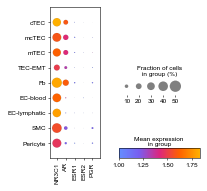

In [24]:
sc.pl.DotPlot(adata, 
            categories_order=stroma_lev2,
            groupby = 'taa_l2_v2',
            var_names=steroid_recs['steroid receptors'],
            figsize = calc_figsize(width = 62, height = 60),
            mean_only_expressed=True,
            cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,), #'magma',
            ).style(smallest_dot=0, largest_dot = 100, dot_edge_lw=0.05).savefig(f'{plot_path}/thyAgeing_stroma_taa_l2_v2-steroid_recs_dotplot.pdf') 

In [15]:
adipognesesis = {
    'Lipogenesis_denovo': ["FASN", "ACLY", "ACACA", "SCD", "ELOVL6"],
    'FA_uptake_transport': ["CD36", "FABP4", "FABP1", "SLC27A1", "SLC27A2", "LPL"],
    'Beta_ox_longchain': ["CPT1A", "CPT1B", "CPT2", "ACADVL", "ACADL", "ACADM", "ACADS", "ACOX1", "ABCD1", "ABCD3"],
    'Ketone_body': ["HMGCS2", "BDH1", "OXCT1"],
    'Lipolysis': ["PNPLA2", "LIPE", "MGLL"],
    'TG_synthesis': ["DGAT1", "DGAT2", "GPAM"],
    'Cholesterol_synthesis': ["HMGCR", "HMGCS1", "SQLE", "MVD", "DHCR7"],
    'Cholesterol_uptake': ["LDLR", "SCARB1"],
    'Cholesterol_efflux': ["ABCA1", "ABCG1", "APOE", "NPC1"],
    'Lipid_efflux_transport': ["ABCA1", "ABCA6", "ABCA8", "ABCA9", "ABCA10", "APOD", "APOE", "LDLR"],
    'Lipid_master_regulators': ["PPARA", "PPARG", "PPARD", "PPARGC1A", "SREBF1", "SREBF2"],
    'Lipid_droplet_storage': ["PLIN1", "PLIN2", "PLIN4", "PLIN5", "CIDEC", "CIDEA", "BSCL2", "FITM1", "FITM2", "CEBPA", "MRAP", "AQP7"],
    'Futile_cycle_uncoupling': ["UCP1", "UCP2", "UCP3"],

}

In [40]:
adipogenesis2 = {'Lipogen and metab': ['FASN', 'ACLY', 'ACADL','PNPLA2'], 
                 'Lipid transport': ['CD36', 'FABP4', 'SLC27A1'], 
                 'Cholesterol': ['LDLR', 'ABCA1', 'ABCG1', 'APOE', 'NPC1'], 
                 'Master reg': ['PPARG', 'CEBPA', 'PPARGC1A', 'SREBF1'], 
                 'Lipid droplet': ['PLIN2', 'PLIN4', 'PLIN5']}

In [16]:
from collections import OrderedDict
inflammation = OrderedDict([
    ('Inflammatory activation', ['CD40', 'TNFRSF12A', 'IL6R', 'IL1RL1', 'IL6ST']),
    ('Cytokines', ['IL6', 'IL18', 'IL33', 'CXCL14', 'CXCL2', 'CCL2', 'CCL21', 'CCL8'])])

In [17]:
from collections import OrderedDict
inflammation2 = OrderedDict([
    ('Inflammatory activation', ['TNFRSF12A', 'PTX3', 'IL6R', 'IL1RL1', 'IL6ST']), # CD40
    ('Cytokines', ['IL6', 'IL18', 'IL33', 'CXCL14', 'CXCL2', 'CCL2', 'CCL21', 'CCL8'])])

In [ ]:
from collections import OrderedDict
mtec_programme = OrderedDict([
    ('signal perecption', ['CD40', 'TNFRSF11A', 'LTBR', 'TNFRSF11B', 'AIRE', 'FEZF2']),
    ('intracellular signalling', ['TRAF6', 'MAP3K14', 'NFKB2', 'RELB', 'NFKB1', 'RELA']),
    ('tfs', ['AIRE', 'FEZF2', 'INSM1', 'SPIB']), 
    ('epigenetic modif', ['NIPBL', 'STAG2', 'CHD4','SMARCA4']),
    ('mature_mrkrs', ['CD80', 'CD86', 'HLA-DRA', 'CCL19', 'CCL21']), 
    ('tras', ['INS', 'CHRNA1', 'CYP1A2', 'PTH', 'TPO', 'MOG'])])

In [27]:
from collections import OrderedDict
mtec_programme = OrderedDict([
    ('signal perecption', ['CD40', 'TNFRSF11A', 'LTBR', 'TNFRSF11B']),
    ('intracellular signalling', ['TRAF6', 'MAP3K14', 'NFKB2', 'RELB', 'NFKB1', 'RELA']),
    ('tfs', ['AIRE', 'FEZF2', 'INSM1', 'SPIB']), 
   # ('epigenetic modif', ['NIPBL', 'STAG2', 'CHD4','SMARCA4']),
    ('mature_mrkrs', ['CD80', 'CD86', 'HLA-DRA', 'CCL19', 'CCL21']), 
   # ('tras', ['INS', 'CHRNA1', 'CYP1A2', 'PTH', 'TPO', 'MOG'])], 
   ('tras', ['INS', 'KRT72', 'LGALS7','AVP',  'TUBB4A'])]) # 'SNCB',

In [21]:
import importlib, de_viz; importlib.reload(de_viz)
from de_viz import plot_de_dotplot3_grouped

<module 'de_viz' from '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts/de_viz.py'>

Celltypes [] are missing
['AKR1C3', 'HSD17B7', 'AKR1C1', 'AKR1C2', 'HSD17B2', 'HSD17B11', 'HSD11B1', 'HSD11B2', 'SULT1A1', 'SULT1E1', 'UGT2B7']
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
['AKR1C3', 'HSD17B7', 'AKR1C1', 'AKR1C2', 'HSD17B2', 'HSD17B11', 'HSD11B1', 'HSD11B2', 'SULT1A1', 'SULT1E1', 'UGT2B7']


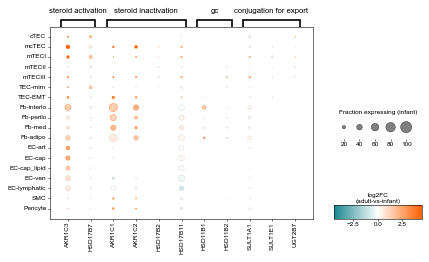

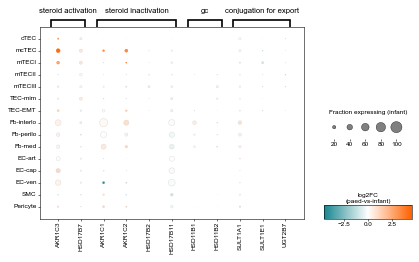

In [ ]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot2_grouped(
        adata = adata, deseq_df = de_df, gene_groups = steroid_process, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing (infant)',
        save_path=f'{plot_path}/de_dotplot_stroma_taa_l3_steroid_process_grouped_{contrast}_vs_infant_{today}.pdf',
        figsize=(6, 3))

Celltypes [] are missing
['AKR1C3', 'HSD17B7', 'AKR1C1', 'AKR1C2', 'HSD17B2', 'HSD17B11', 'HSD11B1', 'HSD11B2', 'SULT1A1', 'SULT1E1', 'UGT2B7']
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
['AKR1C3', 'HSD17B7', 'AKR1C1', 'AKR1C2', 'HSD17B2', 'HSD17B11', 'HSD11B1', 'HSD11B2', 'SULT1A1', 'SULT1E1', 'UGT2B7']


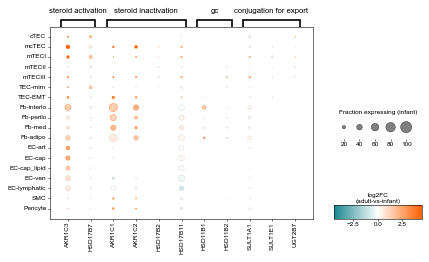

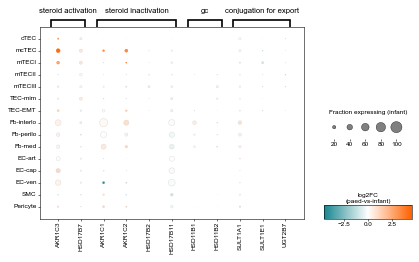

In [ ]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot2_grouped(
        adata = adata, deseq_df = de_df, gene_groups = steroid_process, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing (infant)',
        save_path=f'{plot_path}/de_dotplot_stroma_taa_l3_steroid_process_grouped_{contrast}_vs_infant_{today}.pdf',
        figsize=(6, 3))

4 genes x 18 cell types | figsize 1.94 x 2.66 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
4 genes x 15 cell types | figsize 1.94 x 2.21 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


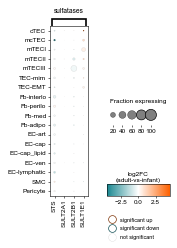

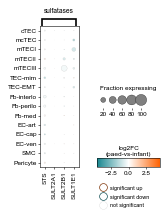

In [31]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = sulfatases, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
        group_label_wrap='auto', group_label_fontsize=6, width_target='single',
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l3_sulfatases_{contrast}_vs_infant_{today}.pdf')

5 genes x 18 cell types | figsize 2.12 x 2.66 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
5 genes x 15 cell types | figsize 2.12 x 2.21 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


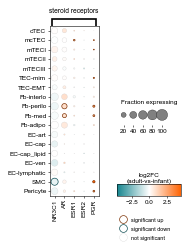

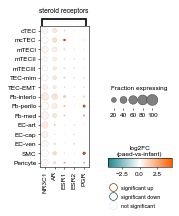

In [ ]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = steroid_recs, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
        group_label_wrap='auto', group_label_fontsize=6, width_target='single',
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l3_steroid_recps_{contrast}_vs_infant_{today}.pdf')

9 genes x 18 cell types | figsize 2.86 x 2.66 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
9 genes x 15 cell types | figsize 2.86 x 2.21 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


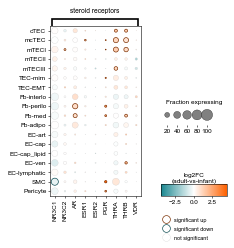

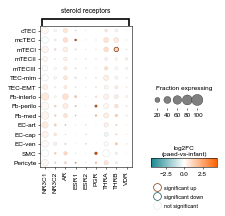

In [84]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = steroid_recs_full, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
        group_label_wrap='auto', group_label_fontsize=6, width_target='single',
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l3_steroid_recps_full_{contrast}_vs_infant_{today}.pdf')

11 genes x 18 cell types | figsize 3.23 x 2.66 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
11 genes x 15 cell types | figsize 3.23 x 2.21 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


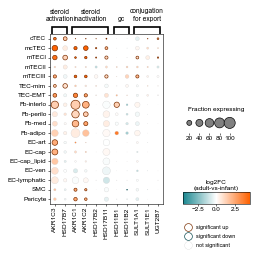

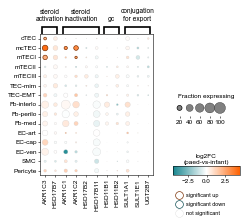

In [ ]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = steroid_process, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
        group_label_wrap='auto', group_label_fontsize=6, width_target='single',
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l3_steroid_process_grouped_{contrast}_vs_infant_{today}.pdf')

Celltypes [] are missing
['FASN', 'ACLY', 'ACACA', 'SCD', 'ELOVL6', 'CD36', 'FABP4', 'FABP1', 'SLC27A1', 'SLC27A2', 'LPL', 'CPT1A', 'CPT1B', 'CPT2', 'ACADVL', 'ACADL', 'ACADM', 'ACADS', 'ACOX1', 'ABCD1', 'ABCD3', 'HMGCS2', 'BDH1', 'OXCT1', 'PNPLA2', 'LIPE', 'MGLL', 'DGAT1', 'DGAT2', 'GPAM', 'HMGCR', 'HMGCS1', 'SQLE', 'MVD', 'DHCR7', 'LDLR', 'SCARB1', 'ABCA1', 'ABCG1', 'APOE', 'NPC1', 'ABCA6', 'ABCA8', 'ABCA9', 'ABCA10', 'APOD', 'PPARA', 'PPARG', 'PPARD', 'PPARGC1A', 'SREBF1', 'SREBF2', 'PLIN1', 'PLIN2', 'PLIN4', 'PLIN5', 'CIDEC', 'CIDEA', 'BSCL2', 'FITM1', 'FITM2', 'CEBPA', 'MRAP', 'AQP7', 'UCP1', 'UCP2', 'UCP3']
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
['FASN', 'ACLY', 'ACACA', 'SCD', 'ELOVL6', 'CD36', 'FABP4', 'FABP1', 'SLC27A1', 'SLC27A2', 'LPL', 'CPT1A', 'CPT1B', 'CPT2', 'ACADVL', 'ACADL', 'ACADM', 'ACADS', 'ACOX1', 'ABCD1', 'ABCD3', 'HMGCS2', 'BDH1', 'OXCT1', 'PNPLA2', 'LIPE', 'MGLL', 'DGAT1', 'DGAT2', 'GPAM', 'HMGCR', 'HMGCS1', 'SQLE', 'MVD', 'DHCR7', 'LDL

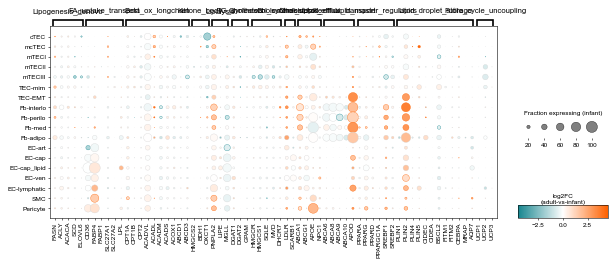

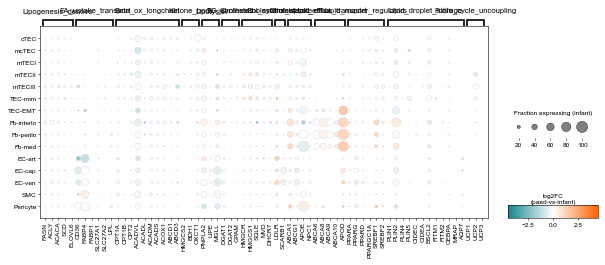

In [30]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot2_grouped(
        adata = adata, deseq_df = de_df, gene_groups = adipognesesis, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing (infant)',
        save_path=f'{plot_path}/de_dotplot_stroma_taa_l3_adipognesesis_grouped_{contrast}_vs_infant_{today}.pdf',
        figsize=(9, 3))

67 genes x 18 cell types | figsize 9.00 x 3.00 in (cell 0.116 x 0.167 in) | dots 0-100 pt^2
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
67 genes x 15 cell types | figsize 9.00 x 3.00 in (cell 0.116 x 0.200 in) | dots 0-100 pt^2


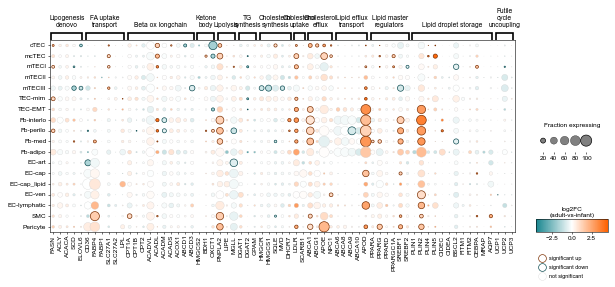

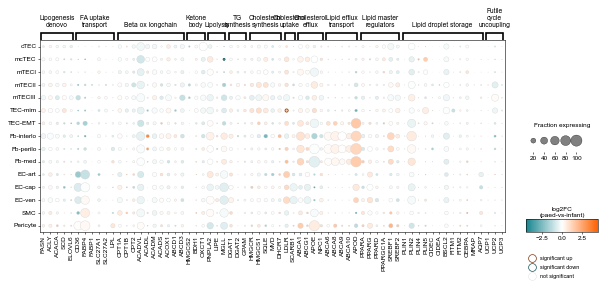

In [69]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = adipognesesis, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
        largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
        group_label_wrap='auto', group_label_fontsize=6, figsize=(9, 3),
        save_path=f'{plot_path}/de_dotplot2.1_stroma_taa_l3_adipognesesis_grouped_{contrast}_vs_infant_{today}.pdf',)

20 genes x 18 cell types | figsize 4.89 x 2.66 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
20 genes x 15 cell types | figsize 4.89 x 2.21 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


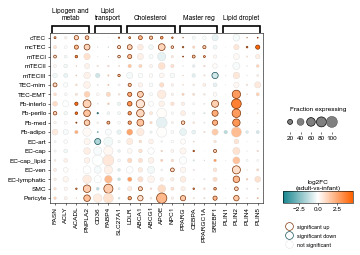

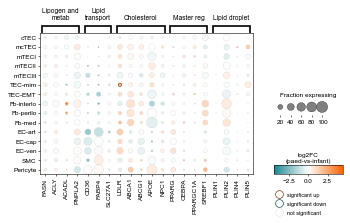

In [36]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = adipogenesis2, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
        largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
        group_label_wrap='auto', group_label_fontsize=6, 
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l3_adipognesesis2_grouped_{contrast}_vs_infant_{today}.pdf',)

13 genes x 18 cell types | figsize 3.60 x 2.66 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
13 genes x 15 cell types | figsize 3.60 x 2.21 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


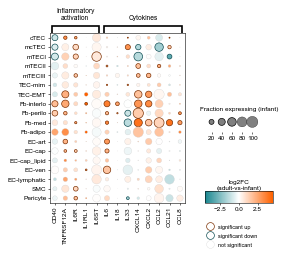

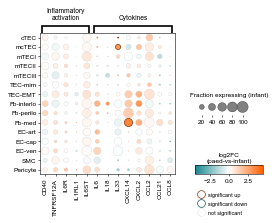

In [70]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = inflammation, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing (infant)',
        largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
                group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot_stroma_taa_l3_inflammation_grouped_{contrast}_vs_infant_{today}.pdf')

Celltypes [] are missing
['CD40', 'TNFRSF12A', 'IL6R', 'IL1RL1', 'IL6ST', 'IL6', 'IL18', 'IL33', 'CXCL14', 'CXCL2', 'CCL2', 'CCL21', 'CCL8']
Celltypes ['EC-cap_lipid' 'EC-lymphatic' 'Fb-adipo'] are missing
['CD40', 'TNFRSF12A', 'IL6R', 'IL1RL1', 'IL6ST', 'IL6', 'IL18', 'IL33', 'CXCL14', 'CXCL2', 'CCL2', 'CCL21', 'CCL8']


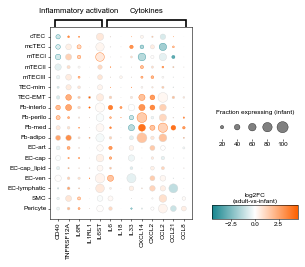

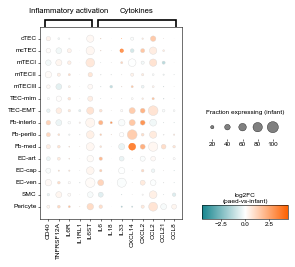

In [ ]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot2_grouped(
        adata = adata, deseq_df = de_df, gene_groups = inflammation, ctypes = DOTPLOT_SUBTYPES3,
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',         save_path=f'{plot_path}/de_dotplot_stroma_taa_l3_inflammation_grouped_{contrast}_vs_infant_{today}.pdf',
        figsize=(4, 3))

In [ ]:
DOTPLOT_SUBTYPES3[0:6]

['cTEC',
 'mcTEC',
 'mTECI',
 'mTECII',
 'mTECIII',
 'TEC-mim',
 'TEC-EMT',
 'Fb-interlo',
 'Fb-perilo',
 'Fb-med',
 'Fb-adipo',
 'EC-art',
 'EC-cap',
 'EC-cap_lipid',
 'EC-ven',
 'EC-lymphatic',
 'SMC',
 'Pericyte']

24 genes x 6 cell types | figsize 5.63 x 0.89 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
24 genes x 6 cell types | figsize 5.63 x 0.89 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


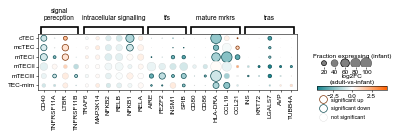

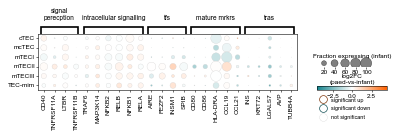

In [28]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = mtec_programme, ctypes = DOTPLOT_SUBTYPES3[0:6],
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing (infant)',
        largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
                group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot_stroma_tec_taa_l3_mTEC_programme_grouped_{contrast}_vs_infant_{today}.pdf')

24 genes x 6 cell types | figsize 5.63 x 0.89 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
24 genes x 6 cell types | figsize 5.63 x 0.89 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


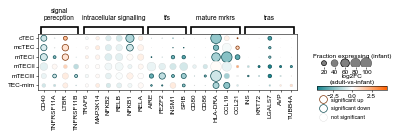

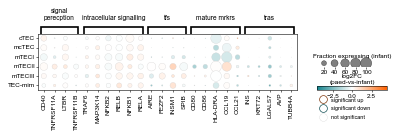

In [29]:
for contrast, de_df in [('adult', de_ad2inf_lev3), ('paed', de_paed2inf_lev3)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = mtec_programme, ctypes = DOTPLOT_SUBTYPES3[0:6],
        ctype_lev='taa_l3', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing (infant)',
        largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
                group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot_stroma_tec_taa_l3_mTEC_programme_grouped_{contrast}_vs_infant_{today}.png')

## Plot changes at taa_l2

4 genes x 9 cell types | figsize 1.94 x 1.33 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
4 genes x 8 cell types | figsize 1.94 x 1.18 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


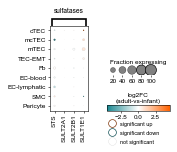

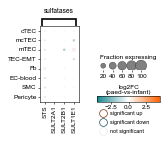

In [32]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = sulfatases, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
         largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
                        group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_sulfatases_grouped_{contrast}_vs_infant_{today}.pdf')

11 genes x 9 cell types | figsize 3.23 x 1.33 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
11 genes x 8 cell types | figsize 3.23 x 1.18 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


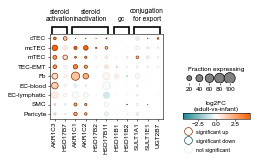

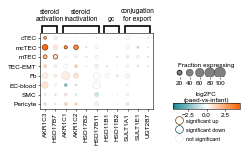

In [ ]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = steroid_process, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
         largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
                        group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_steroid_process_grouped_{contrast}_vs_infant_{today}.pdf')

5 genes x 9 cell types | figsize 2.12 x 1.33 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
5 genes x 8 cell types | figsize 2.12 x 1.18 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


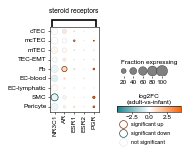

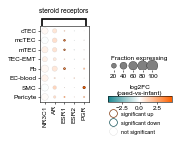

In [86]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = steroid_recs, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
         largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
                        group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_steroid_recs_{contrast}_vs_infant_{today}.pdf')

9 genes x 9 cell types | figsize 2.86 x 1.33 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
9 genes x 8 cell types | figsize 2.86 x 1.18 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


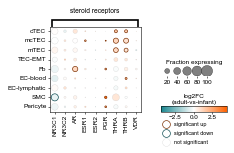

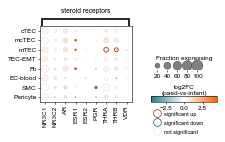

In [87]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = steroid_recs_full, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
         largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
                        group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_steroid_recs_full_{contrast}_vs_infant_{today}.pdf')

11 genes x 9 cell types | figsize 3.23 x 1.33 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
11 genes x 8 cell types | figsize 3.23 x 1.18 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


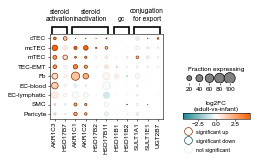

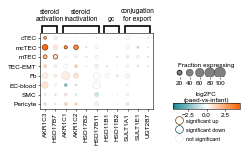

In [76]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = steroid_process, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
         largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
                        group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_steroid_process_grouped_{contrast}_vs_infant_{today}.png')

67 genes x 9 cell types | figsize 7.20 x 0.77 in (cell 0.090 x 0.085 in) | dots 0-24 pt^2
Celltypes ['EC-lymphatic'] are missing
67 genes x 8 cell types | figsize 7.20 x 0.68 in (cell 0.090 x 0.085 in) | dots 0-24 pt^2


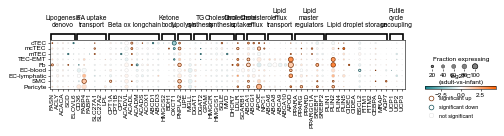

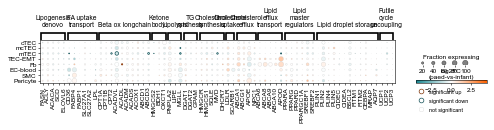

In [73]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = adipognesesis, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
         largest_dot=100, dot_fill = 0.85, row_scale=0.95, edge_scheme='dark',
                        group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_adipognesesis_grouped_{contrast}_vs_infant_{today}.pdf')

67 genes x 9 cell types | figsize 8.00 x 2.30 in (cell 0.101 x 0.256 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
67 genes x 8 cell types | figsize 8.00 x 2.30 in (cell 0.101 x 0.287 in) | dots 0-100 pt^2


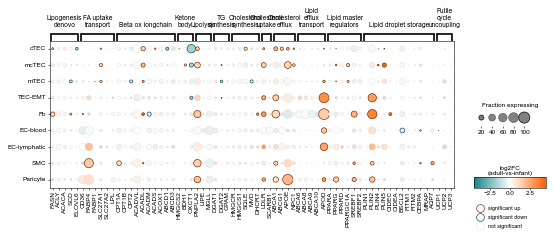

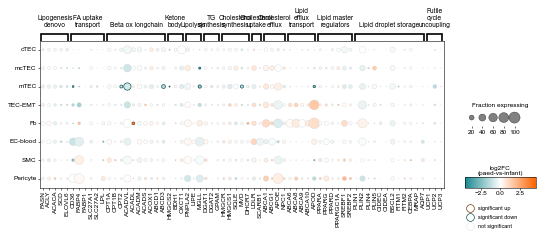

In [80]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = adipognesesis, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
         largest_dot=100, dot_fill = 0.85, row_scale=0.95, edge_scheme='dark',
                        group_label_wrap='auto', group_label_fontsize=6, figsize = (8,2.3),
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_adipognesesis_grouped_{contrast}_vs_infant_{today}.png')

19 genes x 9 cell types | figsize 4.70 x 1.58 in (cell 0.184 x 0.175 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
19 genes x 8 cell types | figsize 4.70 x 1.40 in (cell 0.184 x 0.175 in) | dots 0-100 pt^2


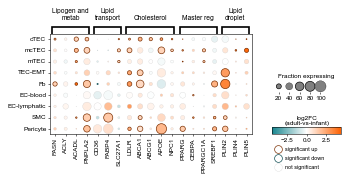

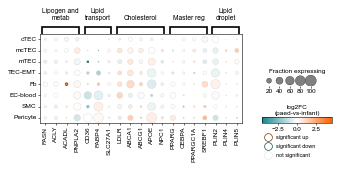

In [43]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = adipogenesis2, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
         largest_dot=100, dot_fill = 0.85, row_scale=0.95, edge_scheme='dark',
                        group_label_wrap='auto', group_label_fontsize=6, #figsize = (8,2.3),
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_adipognesesis2_grouped_{contrast}_vs_infant_{today}.pdf')

13 genes x 9 cell types | figsize 3.60 x 1.33 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
13 genes x 8 cell types | figsize 3.60 x 1.18 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


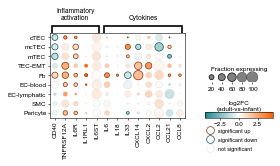

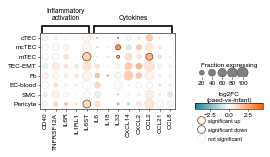

In [75]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = inflammation, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
        largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
        group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_inflammation_grouped_{contrast}_vs_infant_{today}.pdf')

13 genes x 9 cell types | figsize 3.60 x 1.33 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
13 genes x 8 cell types | figsize 3.60 x 1.18 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


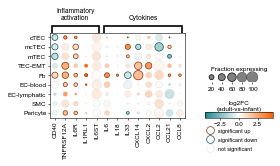

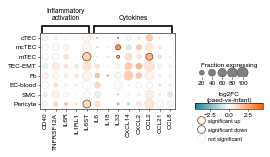

In [79]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = inflammation, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
        largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
        group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_inflammation_grouped_{contrast}_vs_infant_{today}.png')

13 genes x 9 cell types | figsize 3.60 x 1.33 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2
Celltypes ['EC-lymphatic'] are missing
13 genes x 8 cell types | figsize 3.60 x 1.18 in (cell 0.184 x 0.148 in) | dots 0-100 pt^2


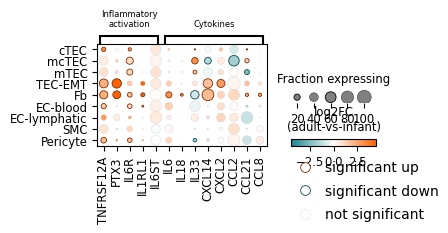

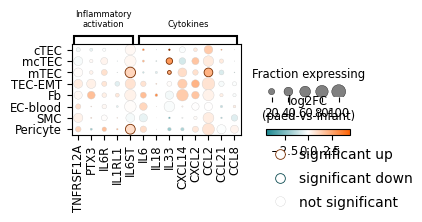

In [21]:
for contrast, de_df in [('adult', de_ad2inf_lev2), ('paed', de_paed2inf_lev2)]:
    dp = plot_de_dotplot3_grouped(
        adata = adata, deseq_df = de_df, gene_groups = inflammation2, ctypes = DOTPLOT_SUBTYPES2,
        ctype_lev='taa_l2_v2', ctype_col='cell_type',
        cbar_title=f'log2FC\n({contrast}-vs-infant)',
        dsize_title='Fraction expressing',
        largest_dot=100, dot_fill = 0.85, row_scale=0.8, edge_scheme='dark',
        group_label_wrap='auto', group_label_fontsize=6,
        save_path=f'{plot_path}/de_dotplot2_stroma_taa_l2_v2_inflammation2_grouped_{contrast}_vs_infant_{today}.pdf')